<p style="font-size: 32px; color: red;">Phase 2.1: Exploration (EDA)</p>

In [4]:
# Load the data and check its shape, columns, and types.
# Summarize: central tendency and spread for numeric columns; value counts for categorical
# ones.
# Visualize distributions with histograms and boxplots and note any early patterns.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statistics as stats


df = pd.read_csv('./nfl_combine_2010_to_2023.csv')
df.head()


,Year,Player,Pos,School,Height,Weight,40yd,Vertical,Bench,Broad Jump,3Cone,Shuttle,Drafted,Round,Pick
0,2010,Seyi Ajirotutu,WR,Fresno State,6-3,204.0,4.60,36.0,14.0,115.0,7.22,4.39,False,NaN,NaN
1,2010,Rahim Alem,DE,LSU,6-3,251.0,4.75,30.5,NaN,106.0,7.54,4.80,False,NaN,NaN
2,2010,Charles Alexander,DT,LSU,6-4,300.0,5.40,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
3,2010,Danario Alexander,WR,Missouri,6-5,215.0,4.62,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
4,2010,Nate Allen,S,South Florida,6-0,207.0,4.50,NaN,16.0,NaN,NaN,NaN,True,2.0,37.0


In [5]:
# Describing the shape, data types, and columns

print(df.shape)
print()
df.info()
combine_cols = ["Year", "Player", "Pos", "School", "Height", "Weight", "40yd", "Vertical", "Bench", "Broad Jump", "3Cone", "Shuttle", "Drafted", "Round", "Pick"]


(4741, 15)

<class 'pandas.DataFrame'>
RangeIndex: 4741 entries, 0 to 4740
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        4741 non-null   int64  
 1   Player      4741 non-null   str    
 2   Pos         4741 non-null   str    
 3   School      4741 non-null   str    
 4   Height      4712 non-null   str    
 5   Weight      4717 non-null   float64
 6   40yd        4194 non-null   float64
 7   Vertical    3731 non-null   float64
 8   Bench       3166 non-null   float64
 9   Broad Jump  3671 non-null   float64
 10  3Cone       2794 non-null   float64
 11  Shuttle     2909 non-null   float64
 12  Drafted     4741 non-null   bool   
 13  Round       3008 non-null   float64
 14  Pick        3008 non-null   float64
dtypes: bool(1), float64(9), int64(1), str(4)
memory usage: 523.3 KB


Phase 2.1.2 Central Tendency, Spreads, and Value Counts

In [6]:
print("-----------------------------------CENTRAL TENDANCY---------------------------------")
print()
summary = df.drop(columns ='Year').describe()
print(summary)
print()
print("-----------------------------------------STD----------------------------------------")
print()
std = df.std(numeric_only=True)
print("Standard Deviation of Numeric Cols")
print(std)
print()
print("-----------------------------------------VAR----------------------------------------")
print()
print("Variance of Numeric Cols")
var = df.var(numeric_only=True)
print(var)

-----------------------------------CENTRAL TENDANCY---------------------------------

            Weight         40yd     Vertical        Bench   Broad Jump  \
count  4717.000000  4194.000000  3731.000000  3166.000000  3671.000000   
mean    241.683909     4.761068    32.926776    20.194251   115.855625   
std      45.384582     0.301064     4.205529     6.432676     9.290842   
min     144.000000     4.220000    17.500000     2.000000    82.000000   
25%     204.000000     4.530000    30.000000    15.000000   110.000000   
50%     231.000000     4.670000    33.000000    20.000000   117.000000   
75%     277.000000     4.950000    36.000000    24.000000   122.000000   
max     384.000000     6.000000    46.500000    49.000000   147.000000   

             3Cone      Shuttle        Round         Pick  
count  2794.000000  2909.000000  3008.000000  3008.000000  
mean      7.251933     4.415895     3.840093   115.872340  
std       0.405234     0.262608     1.915932    70.726114  
min    

In [7]:
# Value Counts For Categorical Values

target_cols = ['Year', 'Player', 'Pos', 'School']

for col in target_cols:
    print(f"------{col}--------")
    print(df[col].value_counts())

------Year--------
Year
2021    464
2020    337
2018    336
2019    336
2014    333
2013    332
2016    332
2011    329
2017    327
2010    326
2012    324
2022    324
2015    322
2023    319
Name: count, dtype: int64
------Player--------
Player
Chris Brown        3
Josh Johnson       3
Chris Jones        3
Anthony Johnson    3
Charles Brown      2
                  ..
Darnell Wright     1
Rejzohn Wright     1
Luke Wypler        1
Bryce Young        1
Cameron Young      1
Name: count, Length: 4700, dtype: int64
------Pos--------
Pos
WR      670
CB      491
RB      426
OT      307
S       306
DT      285
TE      266
DE      261
QB      238
OLB     217
OG      207
LB      179
OL      141
ILB     134
DL      120
C       100
EDGE    100
DB       83
P        81
K        65
FB       42
LS       22
Name: count, dtype: int64
------School--------
School
Alabama                                 144
LSU                                     131
Georgia                                 114
Florida    

2.1.3 Histograms and Boxplots

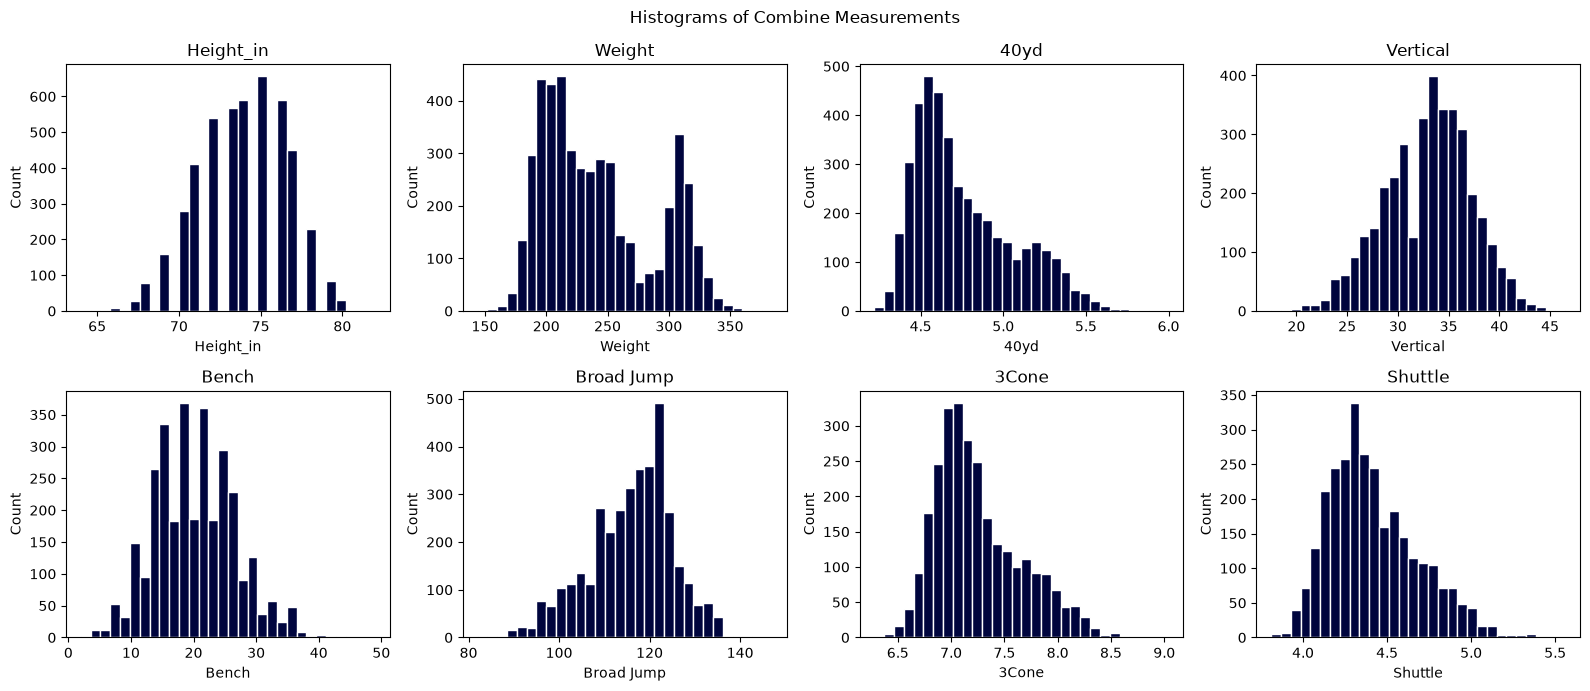

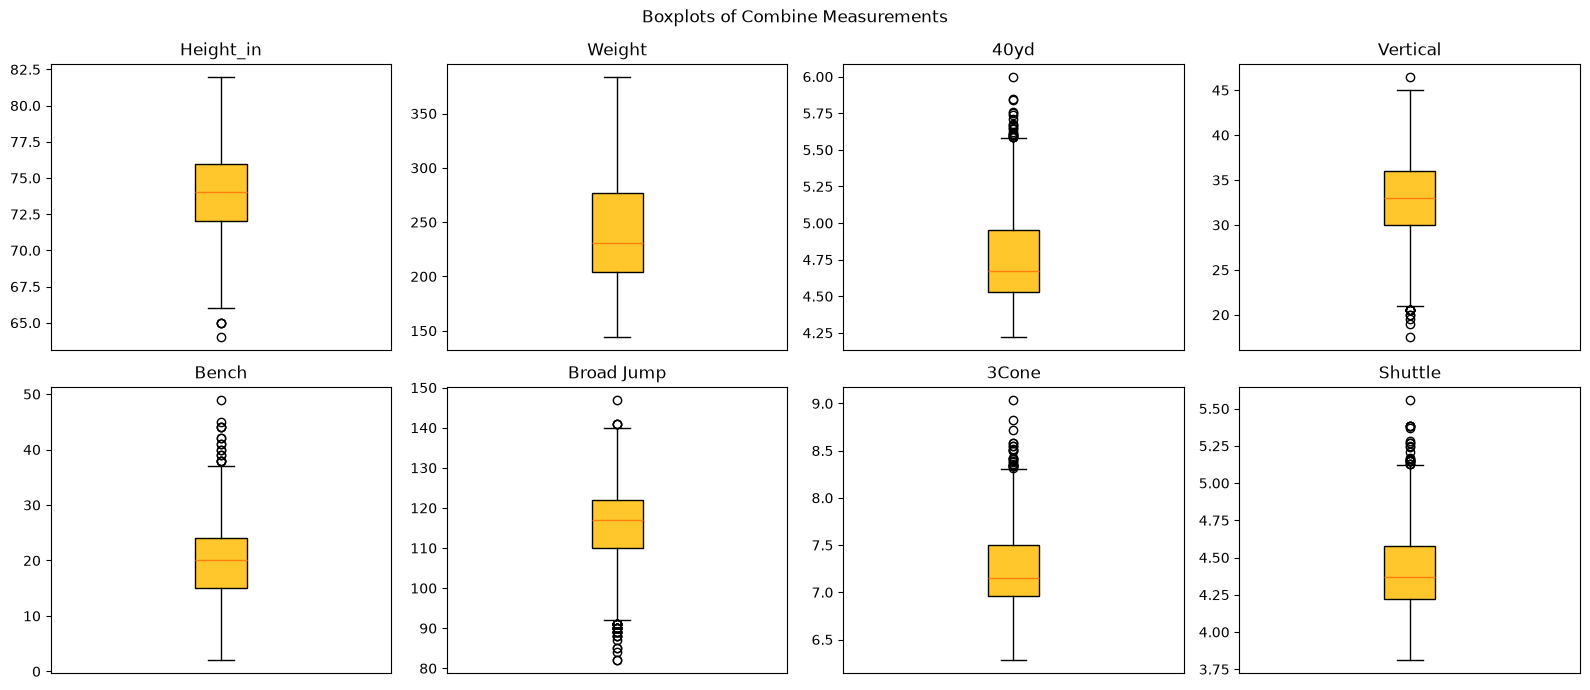

In [ ]:
# Convert Height to inches
def height_to_inches(h):
    try:
        ft, inch = str(h).split("-")
        return int(ft) * 12 + int(inch)
    except ValueError:
        return None

df["Height_in"] = df["Height"].apply(height_to_inches)

cols = ["Height_in", "Weight", "40yd", "Vertical", "Bench",
        "Broad Jump", "3Cone", "Shuttle"]
# Histograms
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cols):
    ax.hist(df[col].dropna(), bins=30, color="#00053E", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel(col); ax.set_ylabel("Count")
plt.suptitle("Histograms of Combine Measurements")
plt.tight_layout()
plt.show()

# Boxplots
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cols):
    ax.boxplot(df[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor="#FFC72C"))
    ax.set_title(col)
    ax.set_xticks([])
plt.suptitle("Boxplots of Combine Measurements")
plt.tight_layout()
plt.show()


We found out that we can't properly display Height due to its original format (e.g. 6-3). Instead, we had to convert that column to where it will measure in inches (6-3 converts to 75 inches). This makes the histogram and box plot look a lot cleaner for that specific column. We also had to drop the column Year in the Central Tendency because year isn't a value that we are trying to quantify or average compared to the other columns.

<p style="font-size: 32px; color: red;">Phase 2.2: Preprocessing</p>

<p style="font-size: 32px; color: red;">Phase 2.3: Analysis</p>